# Level of Effort: Methods and Basis Sets

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/03-level-of-effort.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


No pain, no gain. Every calculation is a choice of **method** (how the electrons interact) and **basis set** (the functions used to build the orbitals). Better choices cost more computer time. In this notebook we optimize water at low, medium and high levels of effort and compare the structures with experiment.

## What You Will Learn
- The main families of **methods**: Hartree–Fock (HF), density functional theory (DFT), MP2 and coupled cluster (CCSD(T)).
- The main families of **basis sets**: minimal (STO-3G), Pople (6-31G*), and correlation-consistent (cc-pVDZ, cc-pVTZ, aug-cc-pVTZ).
- How accuracy and cost change together, and why "more expensive" does not always mean "better" in every property.

The experimental equilibrium structure of water is $r_{\mathrm{OH}} = 0.9578$ Å and $\angle\mathrm{HOH} = 104.48°$ (Hoy and Bunker, *J. Mol. Spectrosc.* **1979**, *74*, 1).

In [2]:
psi4.set_output_file("output/03-level-of-effort.out", False);

r_exp = 0.9578      # Å
a_exp = 104.48      # degrees

## The Levels We Will Compare

| Level | Method / basis | What it adds |
|---|---|---|
| low | HF/STO-3G | Minimal basis: one function per atomic orbital. Fast but crude. |
| low | HF/6-31G | Split valence: two functions for each valence orbital, so orbitals can change size. |
| low | HF/6-31G* | Adds *d* polarization functions on O, so the density can change shape. |
| medium | B3LYP/6-31G* | DFT: includes electron correlation approximately, for about the cost of HF. |
| medium | MP2/cc-pVDZ | Møller–Plesset perturbation theory: the simplest *ab initio* correlation correction. |
| high | MP2/aug-cc-pVTZ | Triple-zeta basis with diffuse ("aug") functions. |
| high | CCSD(T)/cc-pVTZ | Coupled cluster: the "gold standard" for small molecules. |

```{note} Psi4 settings used for these levels
:class: dropdown
`scf_type: "df"`
: Density fitting for the Hartree–Fock part. Fast and accurate to about $10^{-5}$ hartree. It is *Psi4*'s default; we set it explicitly here. *Alternative:* `"pk"` (exact integrals, slower for large basis sets).

`mp2_type: "df"` (default)
: Density-fitted MP2. Much faster than conventional MP2 with negligible error. *Alternative:* `"conv"`.

`freeze_core: True`
: Leaves the oxygen 1s electrons out of the **correlation** treatment (MP2, CCSD(T)). The core electrons barely take part in bonding, and the cc-pVXZ basis sets are not designed to describe core correlation, so freezing them is both cheaper and standard practice. It has no effect on HF or DFT. *Alternative:* `False` together with a core-valence basis set such as cc-pCVTZ, for very high accuracy work.

`cc_type: "conv"` (default for CCSD(T))
: Conventional integrals, required for analytic CCSD(T) gradients in *Psi4*. Density-fitted CCSD(T) (`"df"`) is faster for energies, but its gradients are not available for (T).

DFT integration grid (not set)
: DFT energies are integrated numerically on a grid around each atom. *Psi4*'s default grid (75 radial × 302 angular points) is fine for water. *Alternative:* larger grids, `dft_radial_points: 99` and `dft_spherical_points: 590`, for frequencies of floppy molecules.

Other reasonable choices
: `"pbe0/def2-tzvp"` (a modern hybrid functional and a well-balanced Ahlrichs basis set), `"wb97x-d/def2-tzvp"` (range-separated hybrid with dispersion, good for non-covalent interactions), `"b3lyp-d3bj/def2-svp"` (needs the `dftd3` add-on, which is not installed with *Psi4* by default).
```

In [3]:
psi4.set_options({
    "scf_type": "df",
    "mp2_type": "df",
    "freeze_core": True,
})

levels = [
    ("low",    "hf/sto-3g"),
    ("low",    "hf/6-31g"),
    ("low",    "hf/6-31g*"),
    ("medium", "b3lyp/6-31g*"),
    ("medium", "mp2/cc-pvdz"),
    ("high",   "mp2/aug-cc-pvtz"),
    ("high",   "ccsd(t)/cc-pvtz"),     # about a minute on Colab; comment out if you are in a hurry
]

## Running the Optimizations

Each optimization starts from the same reasonable structure. We use `time.perf_counter()` to measure how long each one takes.

In [4]:
import time

rows = []
for effort, level in levels:
    mol = psi4.geometry("""
    0 1
    O
    H 1 0.96
    H 1 0.96 2 104.5
    """)
    t0 = time.perf_counter()
    E = psi4.optimize(level, molecule=mol)
    seconds = time.perf_counter() - t0

    r = ph.bond_length(mol, 0, 1)
    a = ph.bond_angle(mol, 1, 0, 2)
    rows.append({"effort": effort, "level": level, "time (s)": seconds,
                 "r(O-H) Å": r, "angle °": a,
                 "error r (Å)": r - r_exp, "error angle (°)": a - a_exp})
    print(f"{level:18s} done in {seconds:6.1f} s")

results = pd.DataFrame(rows)
results.round({"time (s)": 1, "r(O-H) Å": 4, "angle °": 2, "error r (Å)": 4, "error angle (°)": 2})

Optimizer: Optimization complete!
hf/sto-3g          done in    1.6 s


Optimizer: Optimization complete!
hf/6-31g           done in    0.9 s


Optimizer: Optimization complete!
hf/6-31g*          done in    0.8 s


Optimizer: Optimization complete!
b3lyp/6-31g*       done in    1.3 s


Optimizer: Optimization complete!
mp2/cc-pvdz        done in    1.0 s


Optimizer: Optimization complete!
mp2/aug-cc-pvtz    done in    1.5 s


Optimizer: Optimization complete!
ccsd(t)/cc-pvtz    done in   16.2 s


,effort,level,time (s),r(O-H) Å,angle °,error r (Å),error angle (°)
0,low,hf/sto-3g,1.6,0.9896,99.98,0.0318,-4.50
1,low,hf/6-31g,0.9,0.9496,111.55,-0.0082,7.07
2,low,hf/6-31g*,0.8,0.9473,105.57,-0.0105,1.09
3,medium,b3lyp/6-31g*,1.3,0.9687,103.62,0.0109,-0.86
4,medium,mp2/cc-pvdz,1.0,0.9650,101.91,0.0072,-2.57
5,high,mp2/aug-cc-pvtz,1.5,0.9611,104.17,0.0033,-0.31
6,high,ccsd(t)/cc-pvtz,16.2,0.9594,103.59,0.0016,-0.89


## Accuracy versus Cost

We plot the size of the error in the bond length and angle against the time taken. The time axis is logarithmic because the cost grows very quickly.

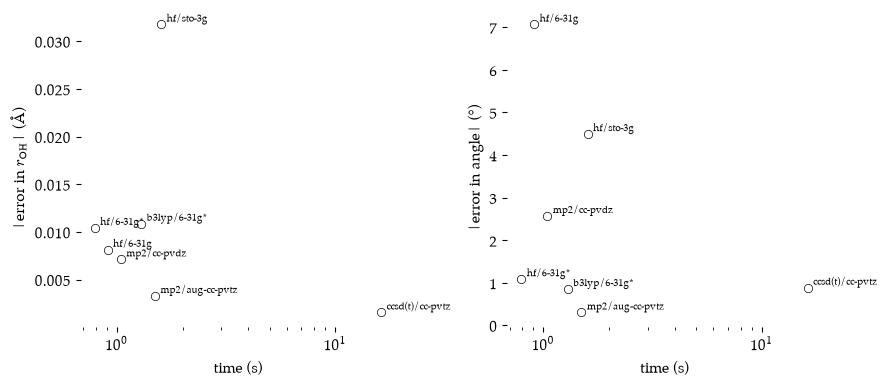

In [5]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))

for ax, col, label in [(axs[0], "error r (Å)", r"|error in $r_{\mathrm{OH}}$| (Å)"),
                       (axs[1], "error angle (°)", "|error in angle| (°)")]:
    ax.plot(results["time (s)"], results[col].abs(), linestyle="none", marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    for _, row in results.iterrows():
        ax.annotate(row["level"], (row["time (s)"], abs(row[col])), fontsize=7,
                    xytext=(4, 2), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("time (s)")
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()

## What the Results Tell Us

- **HF/STO-3G** gives a bond about 0.03 Å too long and an angle about 4.5° too small. A minimal basis set is too inflexible to describe water well.
- **HF/6-31G** fixes the bond length but opens the angle to about 111°, 7° too wide. Without polarization functions the lone pairs cannot pull the hydrogens together.
- Adding **polarization functions** (6-31G → 6-31G*) brings the angle back to within about 1°. This is usually the single most important improvement to a basis set.
- **HF bonds are too short** (about 0.01 Å here) even with a good basis. Hartree–Fock ignores electron correlation, and this error does not go away with a larger basis.
- **B3LYP** and **MP2** include correlation and give longer bonds. With small basis sets they overshoot a little.
- **CCSD(T)/cc-pVTZ** gives the best bond length (within about 0.002 Å), but its angle is still almost 1° too small. Here the **basis set**, not the method, limits the result. MP2/aug-cc-pVTZ gets a better angle, partly because its errors happen to cancel. A higher level is not automatically better for every property.
- CCSD(T) took roughly ten times longer than any other level, even for a three-atom molecule. Its cost rises roughly as the seventh power of molecule size, so it quickly becomes impossible for larger molecules on *Colab*.

```{tip} A practical recipe
For organic molecules, a common compromise is to **optimize** with an affordable method (HF/6-31G* or B3LYP/6-31G*) and then run a single **energy** calculation at a higher level (for example CCSD(T)/cc-pVTZ) on that structure. This is written `CCSD(T)/cc-pVTZ//B3LYP/6-31G*`.
```

## Summary
- Polarization functions matter more than anything else for the structure of water.
- HF has a built-in error (no correlation) that a bigger basis cannot fix.
- Correlated methods (DFT, MP2, CCSD(T)) approach experiment at rapidly increasing cost.
- Always report both the method and the basis set.